Particle in a Box (L = 1.0):
n = 1: Numerical = 4.934786, Analytical = 4.934802, Error = 1.62e-05
n = 2: Numerical = 19.738950, Analytical = 19.739209, Error = 2.59e-04
n = 3: Numerical = 44.411910, Analytical = 44.413220, Error = 1.31e-03
n = 4: Numerical = 78.952696, Analytical = 78.956835, Error = 4.14e-03
n = 5: Numerical = 123.359949, Analytical = 123.370055, Error = 1.01e-02


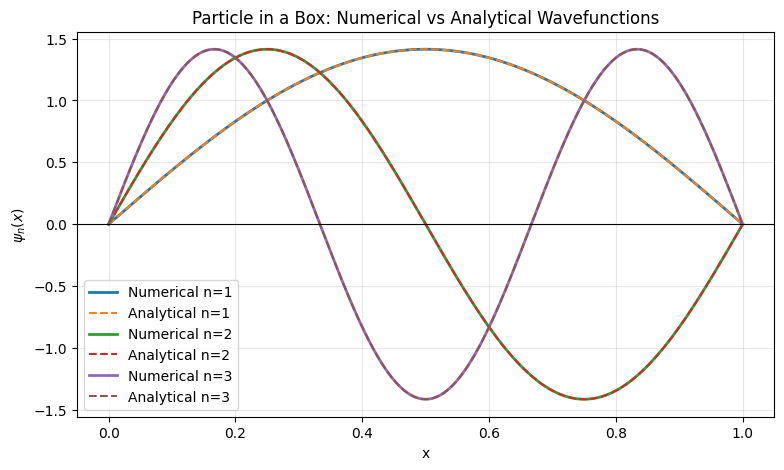

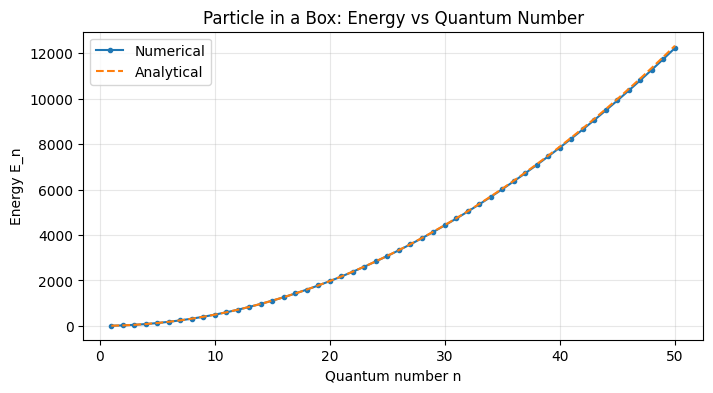

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def build_hamiltonian(dx, V):
    n = len(V)
    main_diag = 1.0 / (dx**2) + V
    off_diag = np.full(n - 1, -0.5 / (dx**2))
    return np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1)

def solve_box(L, N):
    dx = L / (N + 1)
    x_int = dx * np.arange(1, N + 1)
    V = np.zeros(N)
    H = build_hamiltonian(dx, V)
    evals, evecs = np.linalg.eigh(H)

    x_full = np.concatenate(([0.0], x_int, [L]))
    psi_list = []
    for i in range(N):
        psi = np.concatenate(([0.0], evecs[:, i], [0.0]))
        norm = np.sqrt(np.sum(np.abs(psi)**2) * dx)
        psi_list.append(psi / norm)

    return x_full, evals, psi_list

L = 1.0
N = 500
x, E_num, psi_num = solve_box(L, N)

n_vals = np.arange(1, 6)
E_ana = (n_vals**2 * np.pi**2) / (2.0 * L**2)

print("Particle in a Box (L = 1.0):")
for i in range(5):
    err = abs(E_num[i] - E_ana[i])
    print(f"n = {i+1}: Numerical = {E_num[i]:.6f}, Analytical = {E_ana[i]:.6f}, Error = {err:.2e}")

plt.figure(figsize=(9, 5))
for i in range(3):
    n = i + 1
    psi_a = np.sqrt(2.0 / L) * np.sin(n * np.pi * x / L)
    psi_n = psi_num[i]
    if np.dot(psi_n, psi_a) < 0:
        psi_n = -psi_n
    plt.plot(x, psi_n, label=f"Numerical n={n}", linewidth=2)
    plt.plot(x, psi_a, "--", label=f"Analytical n={n}", linewidth=1.5)

plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("x")
plt.ylabel(r"$\psi_n(x)$")
plt.title("Particle in a Box: Numerical vs Analytical Wavefunctions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

n_range = np.arange(1, 51)
E_ana_range = (n_range**2 * np.pi**2) / (2.0 * L**2)

plt.figure(figsize=(8, 4))
plt.plot(n_range, E_num[:50], "o-", markersize=3, label="Numerical")
plt.plot(n_range, E_ana_range, "--", label="Analytical")
plt.xlabel("Quantum number n")
plt.ylabel("Energy E_n")
plt.title("Particle in a Box: Energy vs Quantum Number")
plt.legend()
plt.grid(alpha=0.3)
plt.show()